# Notebook 01 — Per-component panels

For each selected component, produce the standard set of cross-feature-type panels: sample-level scatter, cell-type loading bar, and per-omic loadings laid out by chromosome (RNA / methylation / H3K9ac ChIP).

These are the visual building blocks for every per-component figure in the manuscript. Choose a single component for a focused view, or sweep all 547 to dump panels to disk.

## Required Synapse files

Download version 3 of Synapse dataset `syn75275226` (AD Knowledge Portal). Place all files in a
single directory and set `DEPOSIT_DIR` below. Component IDs are 1–519 and 521–548
(ID 520 is retired), so select components by ID, not by row number.

| File | Shape | Description |
|---|---|---|
| `samples_final.csv` | 547 × 276 | Component × sample loadings |
| `cell_type.csv` | 547 × 6 | Component × cell-type loadings (Ast, Oli, Inh, OPC, Exc, Mic) |
| `RNA.txt` | 25,098 × 547 | Gene × component loadings (PIP > 0.5 masked) |
| `meth.txt` | 51,798 × 547 | CpG × component loadings (PIP > 0.5 masked) |
| `chip.txt` | 26,384 × 547 | H3K9ac peak × component loadings (PIP > 0.5 masked) |

## Required reference annotations

Not bundled with this repository: download the three tables into `references/` (sources and steps in `references/README.md`). The gene annotation is extracted from the Ensembl release 100 GTF; the array manifest and the peak coordinates come with the ROSMAP DNA methylation and H3K9ac ChIP-seq data on the AD Knowledge Portal. All four notebooks load them with the deposit.

| File | Description |
|---|---|
| `Homo_sapiens.GRCh38.100.txt` | Gene annotation (Ensembl 100) |
| `ROSMAP_arrayMethylation_metaData.tsv` | Illumina methylation array manifest |
| `H3K9acDomains.csv` | H3K9ac ChIP-seq peak coordinates (Klein et al.) |

Clinical metadata (`ROSMAP_clinical.csv`) is **not redistributed** — it is
controlled-access (request via the
[AD Knowledge Portal DUC](https://adknowledgeportal.synapse.org/Data%20Access)). Notebooks that need
clinical variables document their dependency inline and degrade gracefully
when the file is absent.


## Setup

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add the repo root to sys.path so we can import the helper module.
sys.path.insert(0, "..")
import g_ros_release as gr

gr.apply_plot_style()


In [2]:
# Path configuration — edit these two paths to match your local layout.
# `DEPOSIT_DIR` is where you downloaded the Synapse files (dataset
# syn75275226, version 3). `REFERENCES_DIR` is the `references/`
# directory in this repo, where you put the reference tables.

# DEPOSIT_DIR is auto-resolved between two common layouts:
#   1. `synapse/` inside the cloned repo (default — what end-users get when
#      they download the deposit into a `synapse/` folder at the repo root)
#   2. `synapse/` as a sibling of the repo (the local-prep layout used to
#      keep code and data physically separate during preparation)
# To override either default, set the env var G_ROS_DEPOSIT_DIR.
import os as _os
DEPOSIT_DIR = _os.environ.get("G_ROS_DEPOSIT_DIR", "../synapse")
if not _os.path.exists(_os.path.join(DEPOSIT_DIR, "samples_final.csv")):
    _fallback = "../../synapse"
    if _os.path.exists(_os.path.join(_fallback, "samples_final.csv")):
        DEPOSIT_DIR = _fallback
        print(f"[notebook] using sibling deposit layout: {DEPOSIT_DIR}")
REFERENCES_DIR = _os.environ.get("G_ROS_REFERENCES_DIR", "../references")   # see references/README.md

deposit = gr.load_deposit(DEPOSIT_DIR, REFERENCES_DIR, load_references=True)
print(f"Loaded {len(deposit.samples)} components × {deposit.samples.shape[1]} samples")


Loaded 547 components × 276 samples


## Configuration

In [3]:
# Choose which components to run. Defaults to the nine components shown
# in the manuscript figures. To sweep all 547 components, replace with:
#     COMPONENTS = list(deposit.samples.index)   # IDs 1–519 and 521–548
# To run a single component, e.g. just Component 74:
#     COMPONENTS = [74]
#
# Components and their manuscript figure (also in gr.HEADLINE_COMPONENTS):
#    74: Figure 2 (sex-associated regulatory variation)
#   278: Figure 3 (sex-biased component shared by OPCs and oligodendrocytes)
#   172: Figure 4 (neuron-dominated; neuritic plaque burden)
#   277: Figure 5 (neuron-dominated; clinical Alzheimer's dementia)
#    21: Sup Fig S2 (olfactory receptor expression and its cis-genetic regulation)
#   351: Sup Fig S8 (single-individual multi-omic profile)
#     2: Sup Fig S9 (single-individual multi-omic profile)
#    87: Sup Fig S10 (single-individual multi-omic profile)
#   177: Sup Fig S11 (dominated by one donor)

COMPONENTS = [74, 278, 172, 277, 21, 351, 2, 87, 177]

# Where to save figures. Set to None to display inline only.
SAVE_FIGURES_DIR = None  # e.g. "./out/panels"

if SAVE_FIGURES_DIR is not None:
    os.makedirs(SAVE_FIGURES_DIR, exist_ok=True)


## Optional: clinical metadata for sex overlay on the sample scatter

If `ROSMAP_clinical.csv` is in `REFERENCES_DIR`, the sample scatter colour-codes points by sex and sorts by age at death. Otherwise it falls back to a default plot.

In [4]:
clin_path = os.path.join(REFERENCES_DIR, 'ROSMAP_clinical.csv')
if os.path.exists(clin_path):
    clinical_df = pd.read_csv(clin_path, index_col=0)
    print(f'Loaded clinical metadata: {clinical_df.shape}')
else:
    clinical_df = None
    print('ROSMAP_clinical.csv not present — sample scatter will run without sex/age annotation.')


ROSMAP_clinical.csv not present — sample scatter will run without sex/age annotation.


## Per-component annotation joins

We pre-build the gene / methylation / ChIP annotation tables once, in the format expected by `gr.plot_loadings_by_chromosome`. These are reused across every component.

In [5]:
# Gene annotation (RNA): index by gene symbol, with chrom + chromStart
gene_annot = deposit.references['gene_annot']
gene_annot = gene_annot.assign(label=gene_annot['gene_name'])
gene_annot.index = gene_annot['gene_name']
rna_annot = gene_annot[['chrom', 'chromStart', 'label']]

# Methylation annotation: chr + position + composite label
meth_annot = deposit.references['meth_annot'].copy()
meth_annot['CHR'] = meth_annot['CHR'].astype(str)
meth_annot['label'] = meth_annot.apply(
    lambda r: f"{r.name}:{str(r['RefGene']).split(';')[0]}" if pd.notna(r.get('RefGene')) else r.name,
    axis=1,
)
meth_annot_sub = meth_annot[['CHR', 'MAPINFO', 'label']]

# ChIP annotation: chromosome + start + classification label
chip_annot = deposit.references['chip_annot'].copy()
chip_annot['Chr'] = chip_annot['Chr'].astype(str)
chip_annot['label'] = chip_annot.apply(
    lambda r: f"{r.name}:{r['Classification']}", axis=1,
)
chip_annot_sub = chip_annot[['Chr', 'Start', 'label']]


## Helper — produce all panels for one component

In [6]:
def produce_panels(component_id: int, save_dir: str | None = None) -> None:
    """Produce sample scatter + cell-type bar + per-omic chromosome plots.

    Plots are shown inline. If `save_dir` is given, each panel is also
    saved as a PDF under `<save_dir>/<component_id>/<panel>.pdf`.
    """
    # adjustText shifts exactly overlapping labels at random: fix the seed per component.
    np.random.seed(component_id)
    s = gr.component_summary(deposit, component_id)
    print(f"\n=== Component {component_id} — {s['manuscript_role']} ===")
    print(f"  top+={s['top_celltype_pos'] or 'none'}, top-={s['top_celltype_neg'] or 'none'}, "
          f"PIP-features RNA={s['n_features_RNA']} meth={s['n_features_meth']} "
          f"chip={s['n_features_chip']}")

    if save_dir is not None:
        comp_dir = os.path.join(save_dir, str(component_id))
        os.makedirs(comp_dir, exist_ok=True)
    else:
        comp_dir = None

    # Sample scatter
    fig = plt.figure(figsize=(8, 4))
    ax = fig.add_subplot(111)
    gr.plot_sample_scatter(deposit, component_id, sample_metadata=clinical_df, ax=ax)
    if comp_dir is not None:
        plt.savefig(os.path.join(comp_dir, 'samples.pdf'), bbox_inches='tight')
    plt.show()

    # Cell-type bar
    fig, ax = plt.subplots(figsize=(6, 4))
    gr.plot_celltype_bar(deposit, component_id, ax=ax)
    plt.tight_layout()
    if comp_dir is not None:
        plt.savefig(os.path.join(comp_dir, 'cell_type.pdf'), bbox_inches='tight')
    plt.show()

    # Per-omic chromosome scatters (skip if no PIP-significant features)
    omic_specs = [
        ('RNA',      rna_annot,         'chrom',      'chromStart', 'label'),
        ('meth',     meth_annot_sub,    'CHR',        'MAPINFO',    'label'),
        ('chip',     chip_annot_sub,    'Chr',        'Start',      'label'),
    ]
    for omic, annot, chrom_col, pos_col, label_col in omic_specs:
        n_feats = int(deposit.genes[omic][component_id].notna().sum())
        if n_feats == 0:
            print(f"  [{omic}] no PIP-significant features for component {component_id}; skipping.")
            continue
        fig, ax = plt.subplots(figsize=(12, 4))
        gr.plot_loadings_by_chromosome(
            deposit, component_id, omic=omic,
            feature_annot=annot,
            chrom_col=chrom_col, pos_col=pos_col, label_col=label_col,
            ax=ax,
        )
        plt.tight_layout()
        if comp_dir is not None:
            plt.savefig(os.path.join(comp_dir, f'{omic}.pdf'), bbox_inches='tight')
        plt.show()


## Run on selected components

When `COMPONENTS` is large (e.g., a full sweep of all 547 components), set `SAVE_FIGURES_DIR` to a directory and consider running this loop from the command line instead — running 547 × ~6 plots inline in a notebook is slow and memory-hungry.


=== Component 74 — Figure 2: sex-associated regulatory variation ===
  top+=Oli, top-=none, PIP-features RNA=161 meth=3435 chip=676


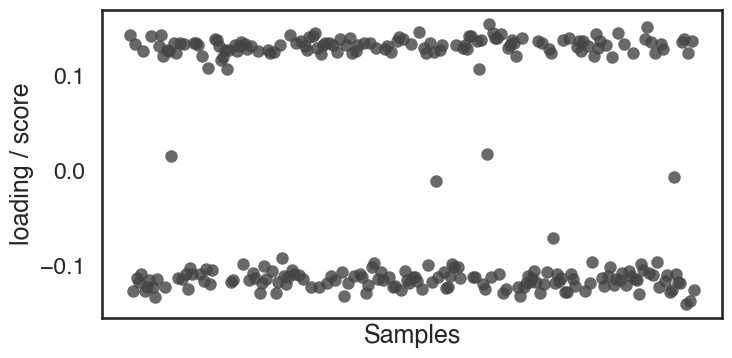

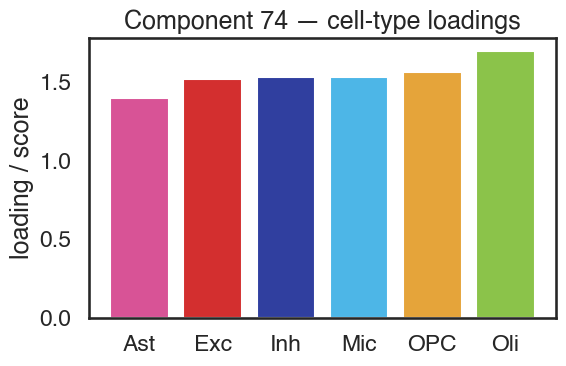

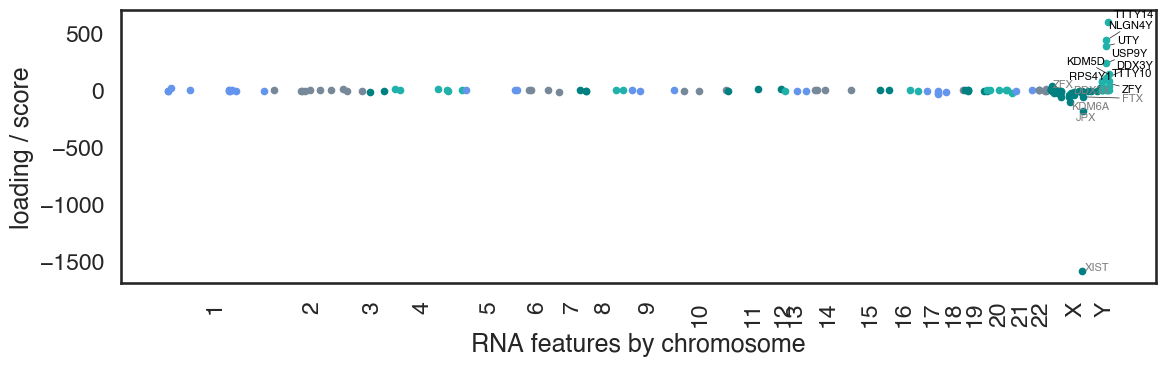

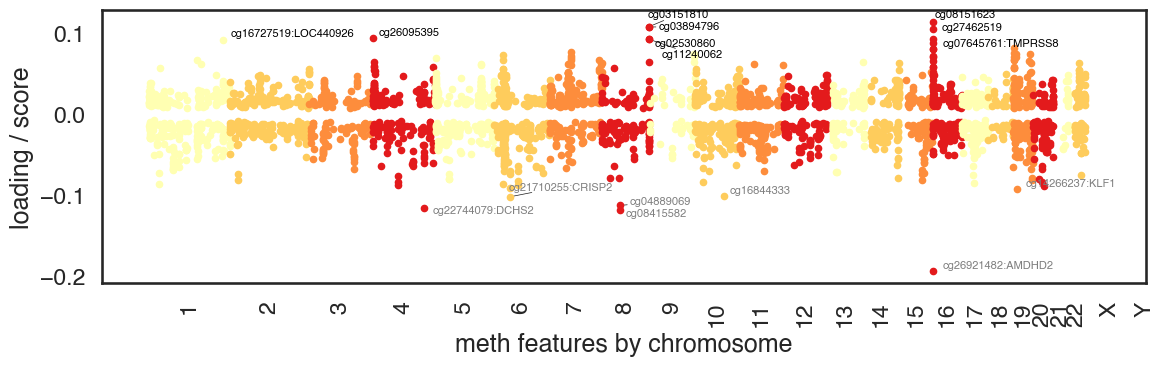

0 [-0.59559541  0.56909521]
7 [ 0.72107448 -0.3458296 ]


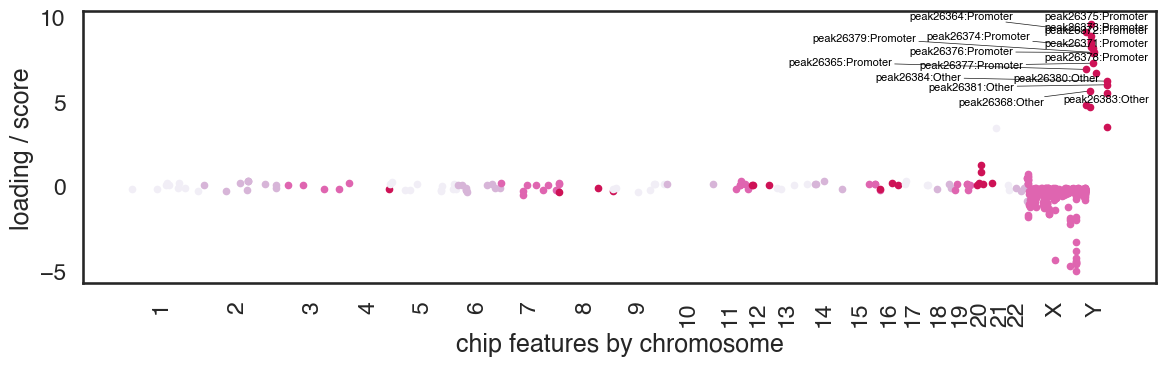


=== Component 278 — Figure 3: sex-biased component shared by OPCs and mature oligodendrocytes ===
  top+=none, top-=OPC, PIP-features RNA=1114 meth=0 chip=0


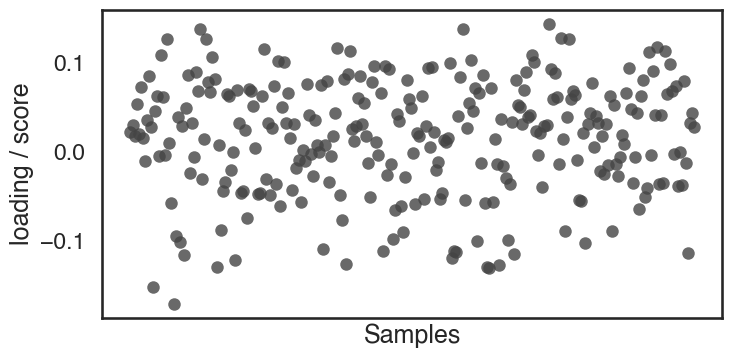

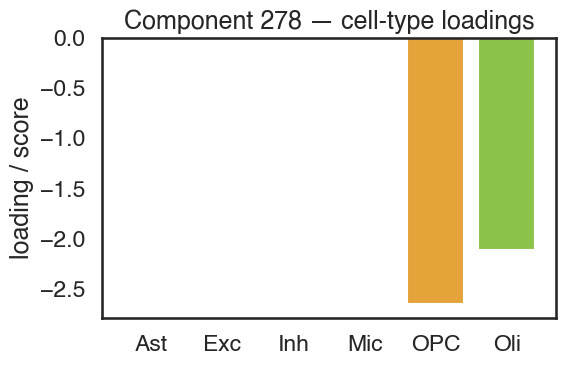

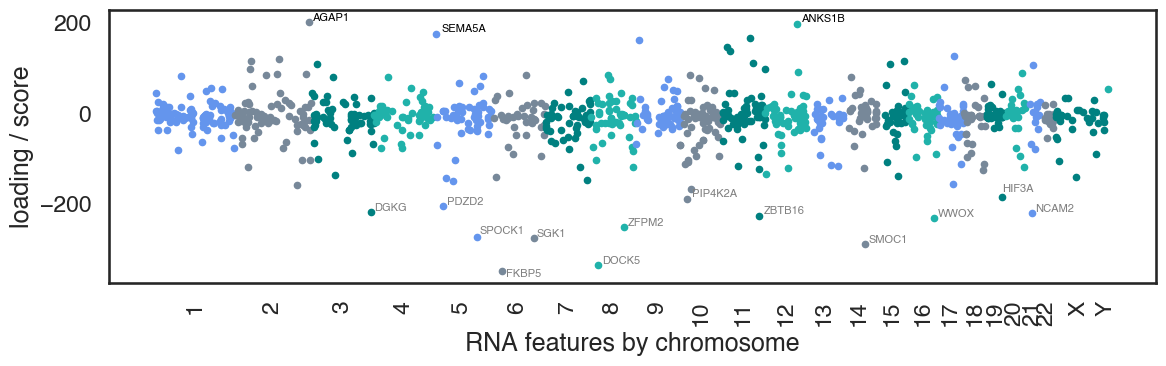

  [meth] no PIP-significant features for component 278; skipping.
  [chip] no PIP-significant features for component 278; skipping.

=== Component 172 — Figure 4: neuron-dominated component associated with neuritic plaque burden ===
  top+=none, top-=Inh, PIP-features RNA=1013 meth=0 chip=0


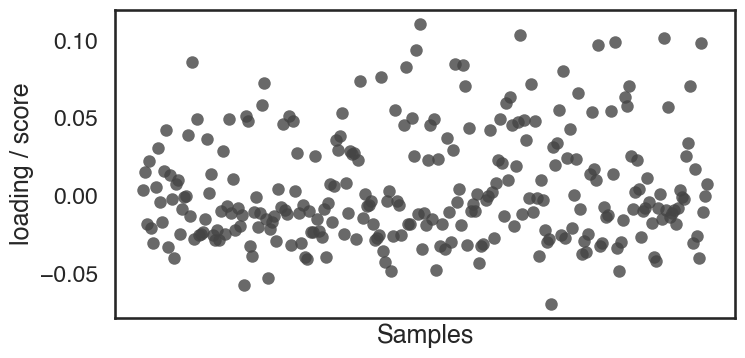

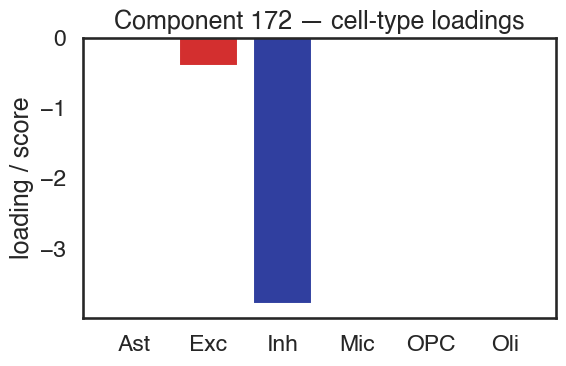

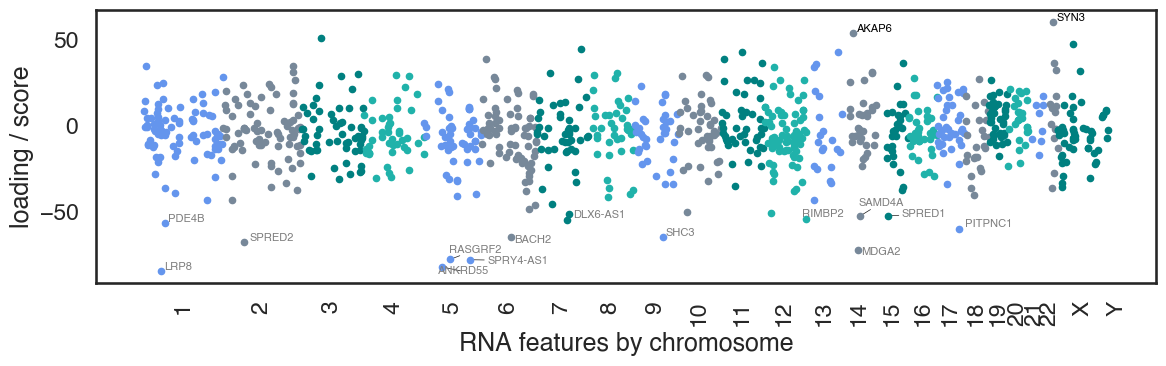

  [meth] no PIP-significant features for component 172; skipping.
  [chip] no PIP-significant features for component 172; skipping.

=== Component 277 — Figure 5: neuron-dominated component associated with clinical Alzheimer's dementia ===
  top+=none, top-=Exc, PIP-features RNA=1180 meth=0 chip=0


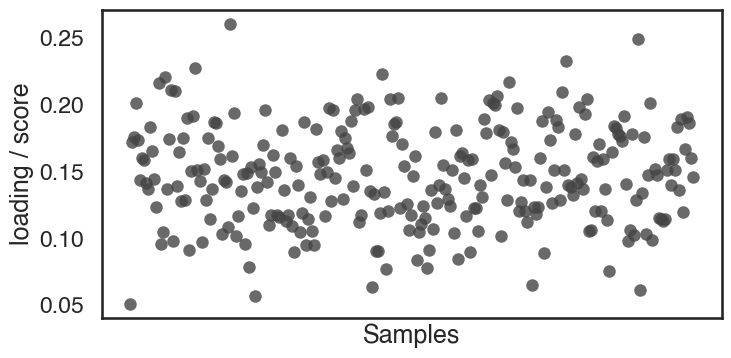

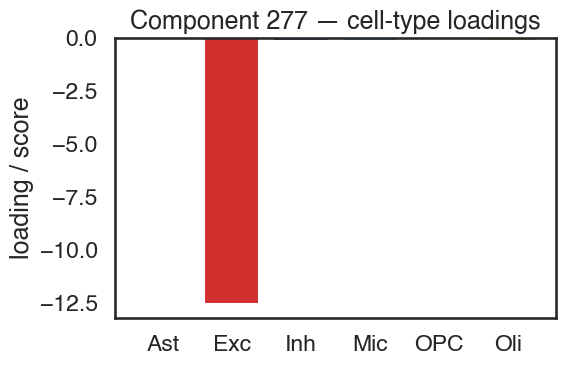

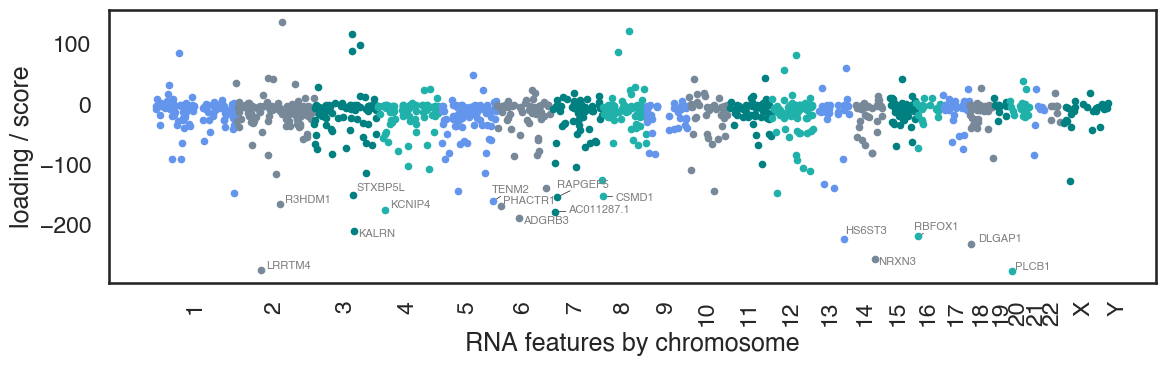

  [meth] no PIP-significant features for component 277; skipping.
  [chip] no PIP-significant features for component 277; skipping.

=== Component 21 — Supplementary Figure S2: ectopic olfactory receptor expression and its cis-genetic regulation ===
  top+=none, top-=Exc, PIP-features RNA=555 meth=0 chip=0


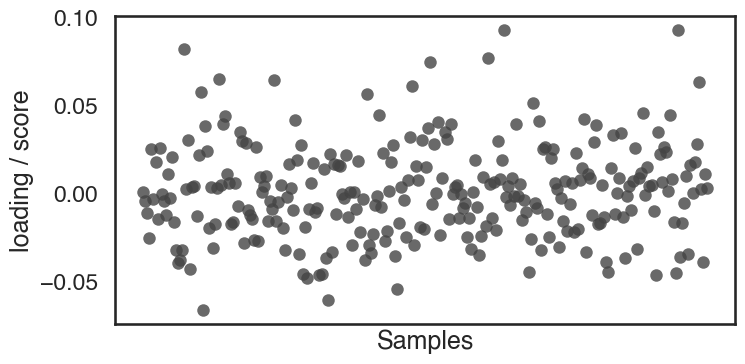

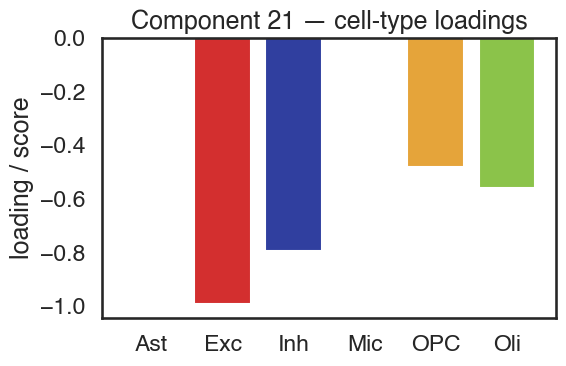

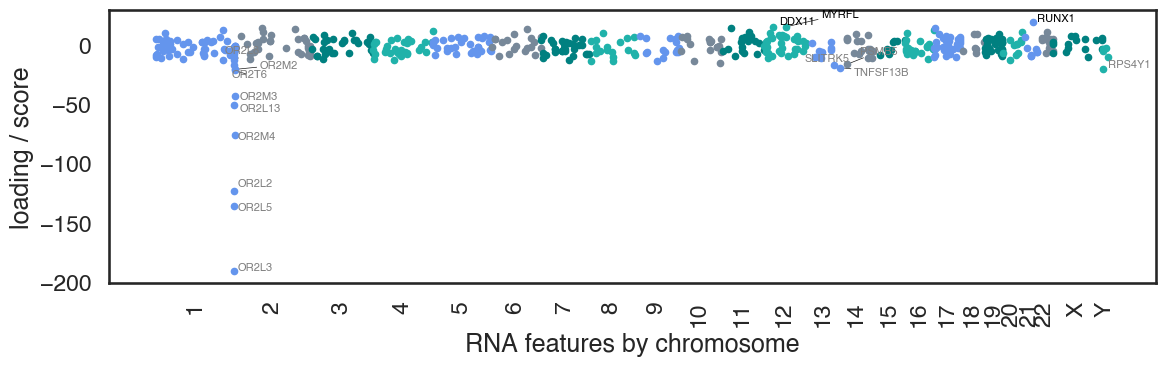

  [meth] no PIP-significant features for component 21; skipping.
  [chip] no PIP-significant features for component 21; skipping.

=== Component 351 — Supplementary Figure S8: a single-individual multi-omic profile ===
  top+=Mic, top-=none, PIP-features RNA=707 meth=7 chip=584


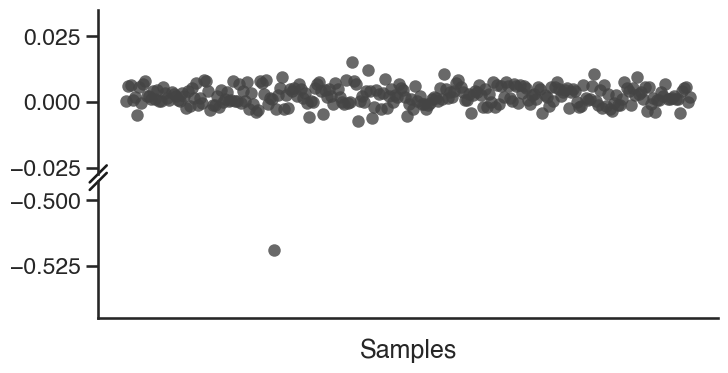

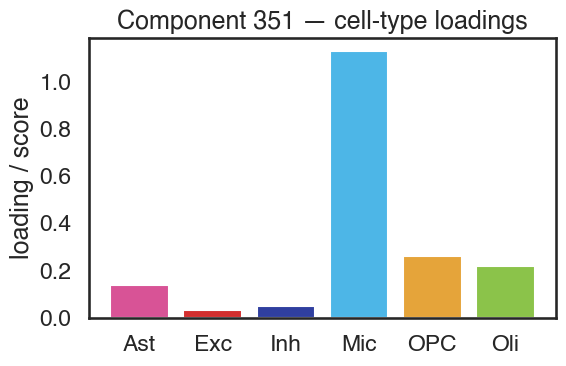

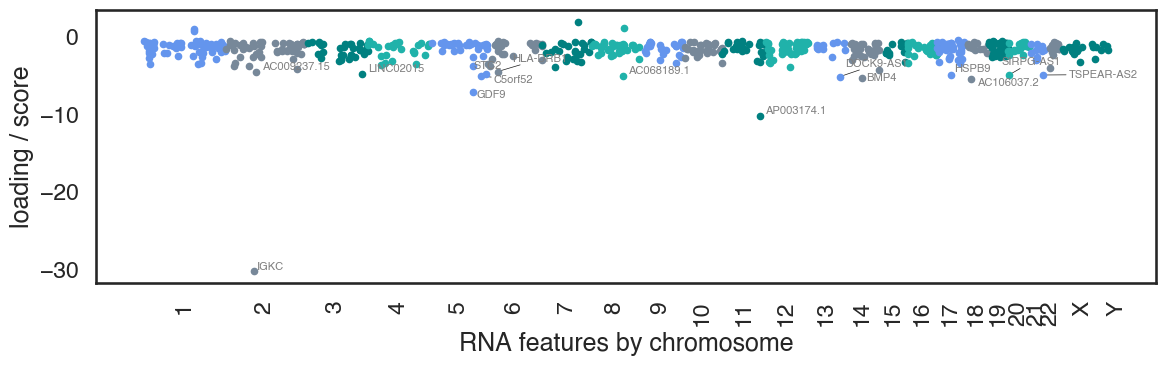

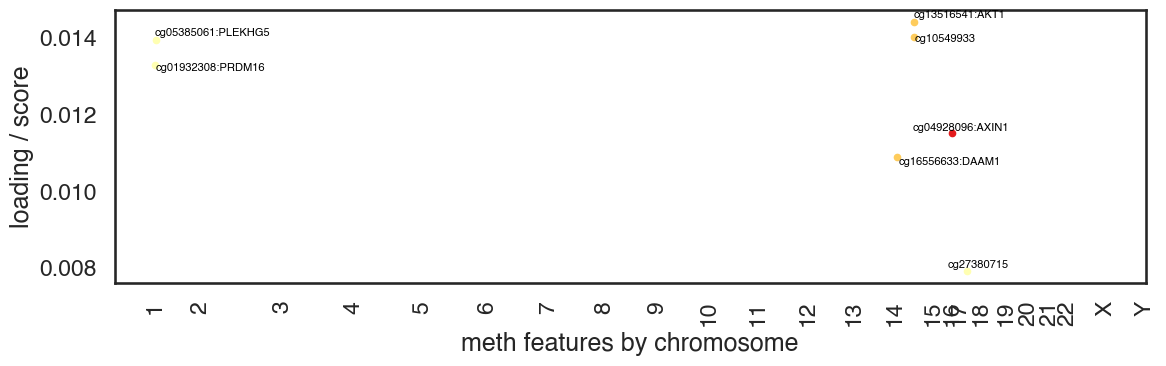

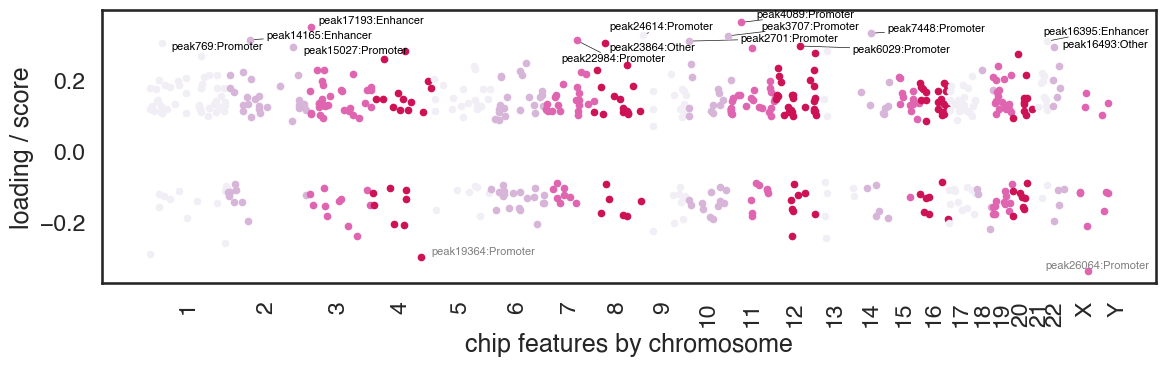


=== Component 2 — Supplementary Figure S9: a single-individual multi-omic profile ===
  top+=none, top-=Mic, PIP-features RNA=277 meth=6 chip=7


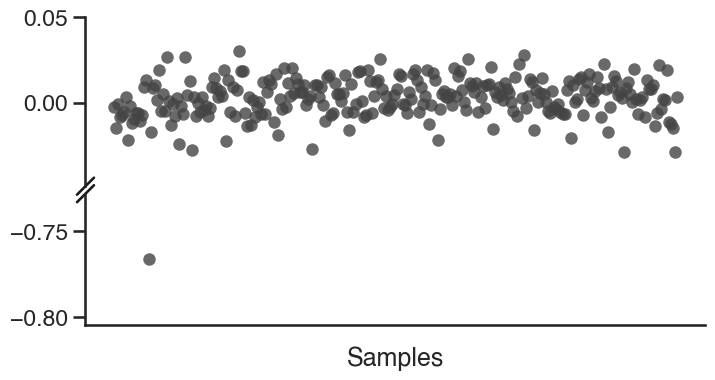

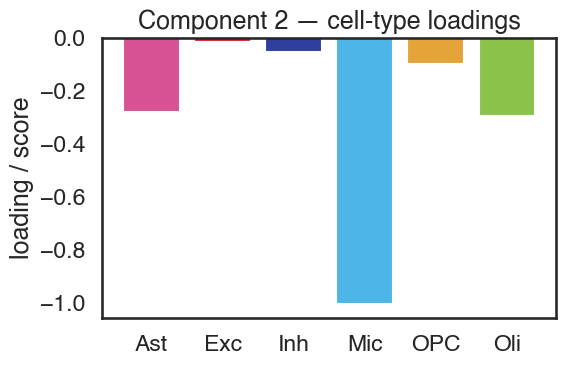

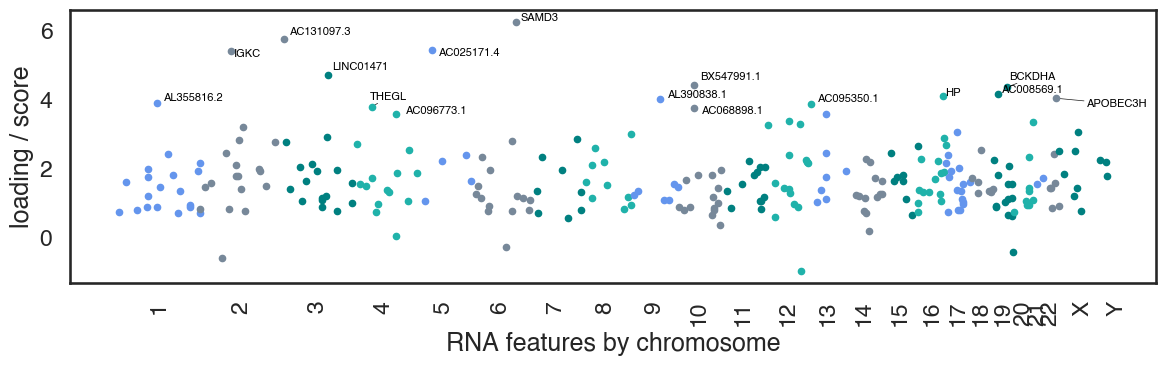

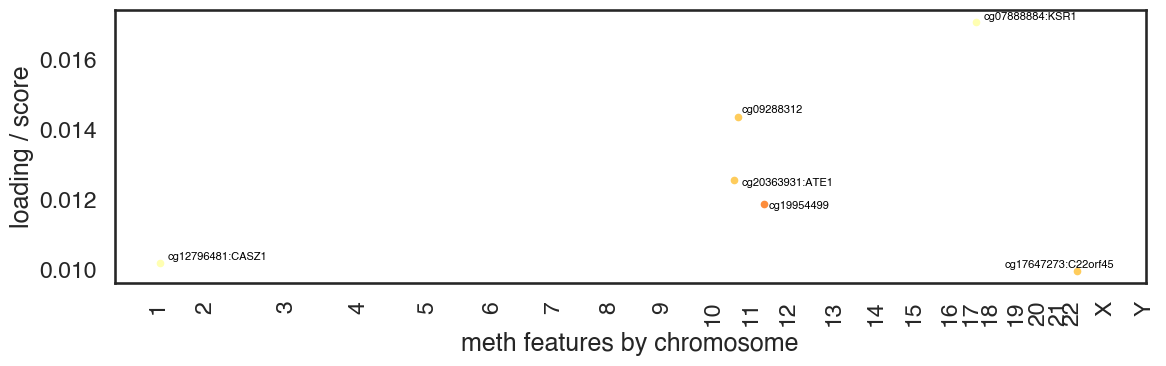

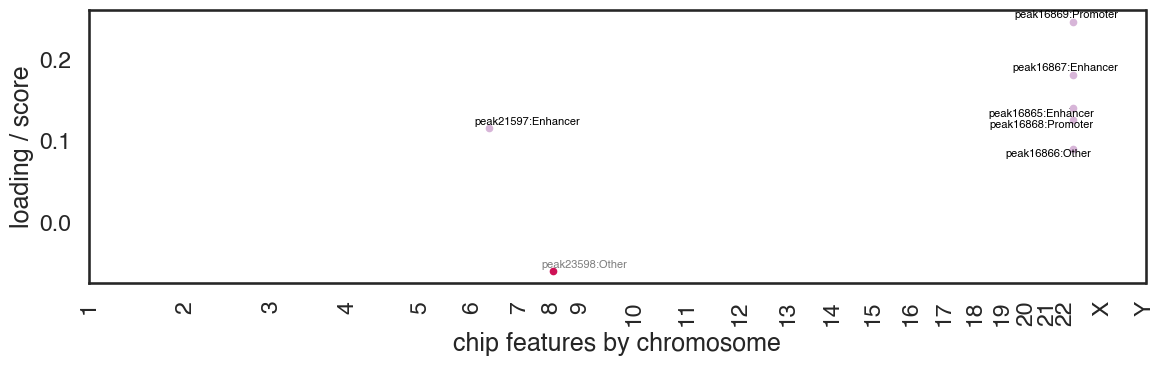


=== Component 87 — Supplementary Figure S10: a single-individual multi-omic profile ===
  top+=none, top-=Ast, PIP-features RNA=255 meth=2 chip=2


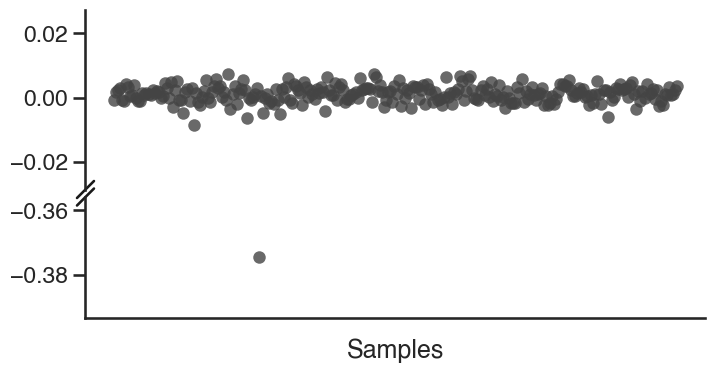

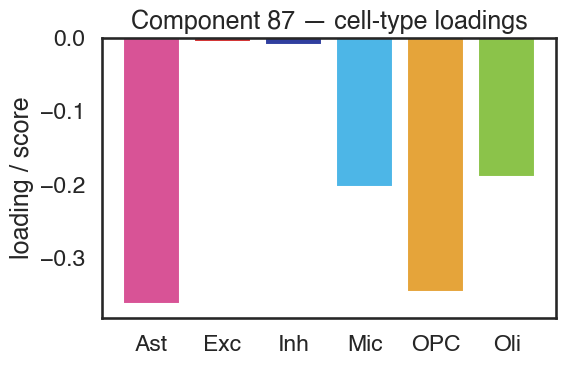

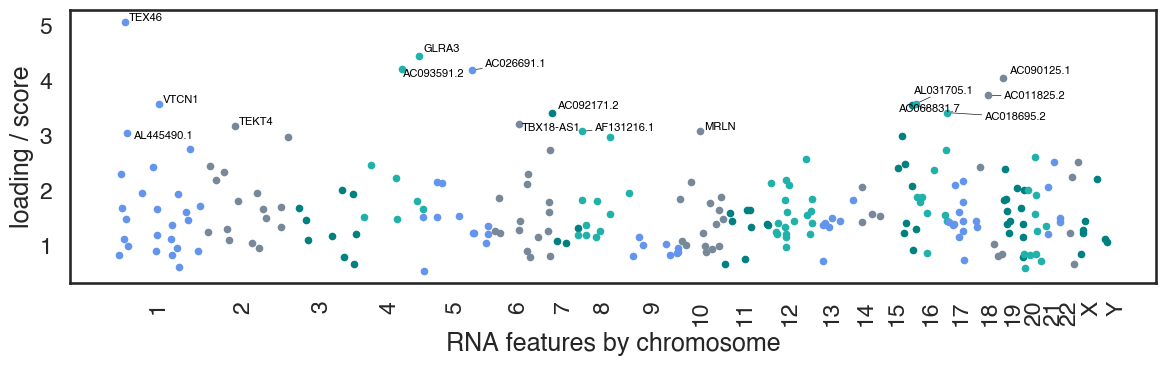

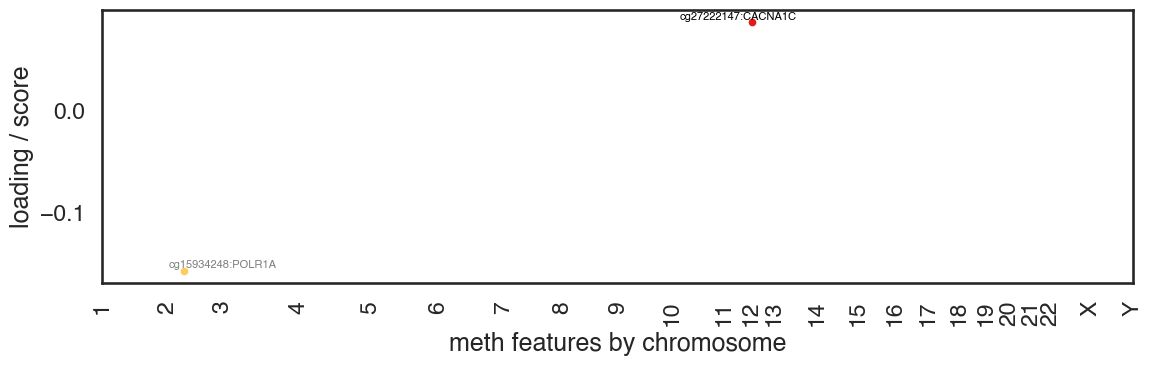

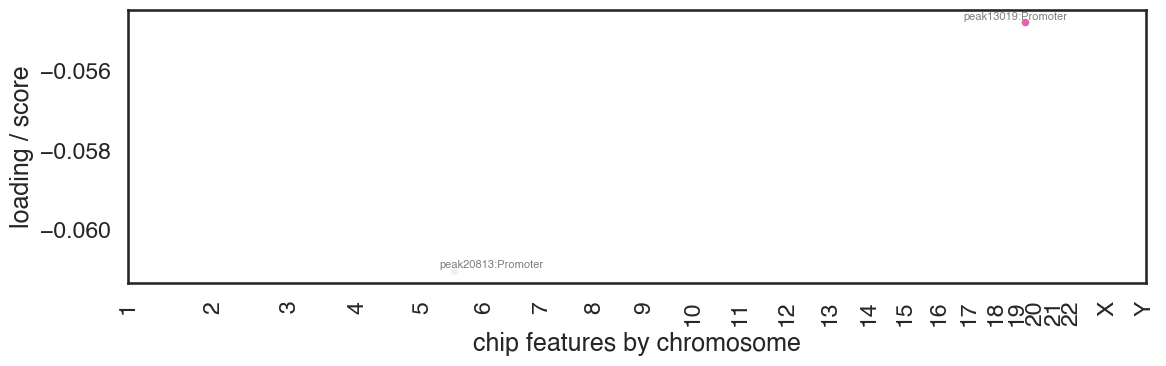


=== Component 177 — Supplementary Figure S11: a component dominated by one donor ===
  top+=none, top-=Mic, PIP-features RNA=155 meth=8 chip=0


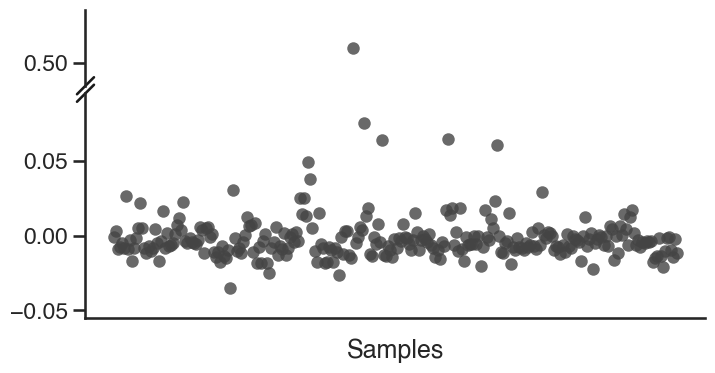

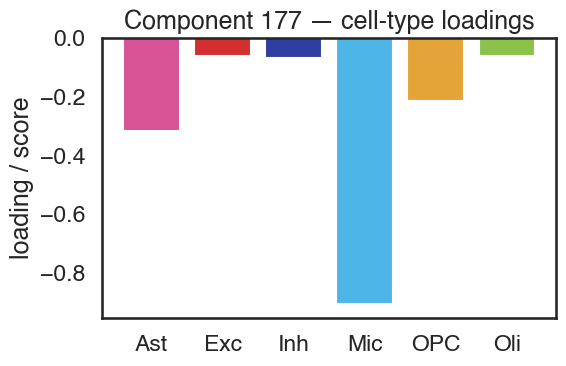

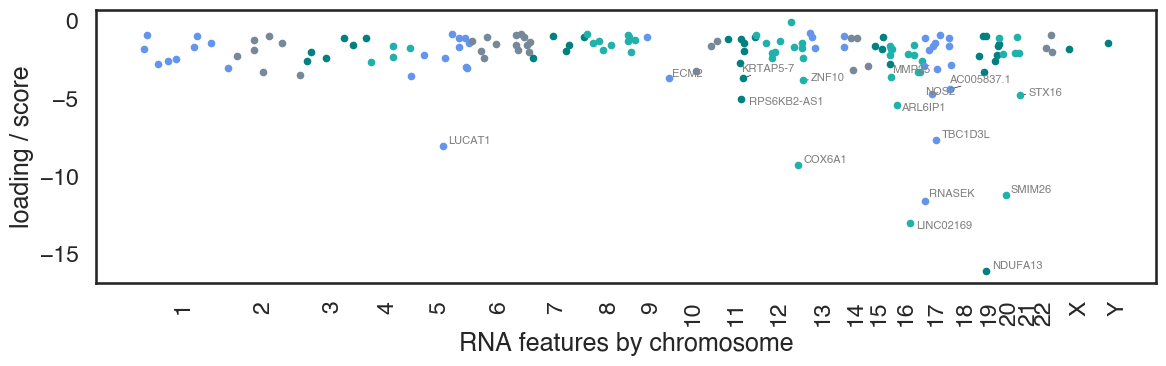

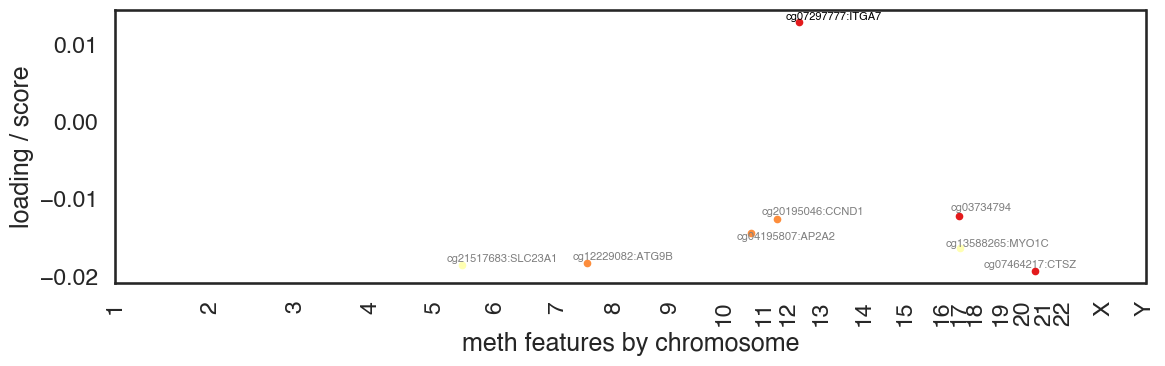

  [chip] no PIP-significant features for component 177; skipping.


In [7]:
for cid in COMPONENTS:
    if not deposit.has_component(cid):
        print(f'Component {cid} not in deposit; skipping.')
        continue
    produce_panels(cid, save_dir=SAVE_FIGURES_DIR)


## Notes

**Sign convention.** SDA components are sign-arbitrary only for sign changes that leave every reconstructed product unchanged: a component's sample loadings can be multiplied by −1 together with all of its feature loadings (genes, CpGs, peaks, proteins), or its cell-type loadings together with its gene loadings. The manuscript figures plot the deposited values as they are, so a notebook panel and the corresponding manuscript panel should match without any sign change.

**Reproducing manuscript figures.** The per-component figures are Fig 2 → 74, Fig 3 → 278, Fig 4 → 172, Fig 5 → 277, Sup S2 → 21, Sup S8 → 351, Sup S9 → 2, Sup S10 → 87 and Sup S11 → 177. After running this notebook for the relevant component, the saved PDFs (or inline outputs) give the figure's cell-type and loading panels.